# Example 2: Double quantum dot initialization

Authors: C. Ventura-Meinersen and D. Fernandez-Fernandez

Below we import the necesary libraries for this example file:

In [1]:
import warnings

import matplotlib.pyplot as plt
import numpy as np

import geodesiq as gq

# Show warnings as "Category: message", without the path of the kernel's temporary file.
warnings.formatwarning = lambda message, category, *args, **kwargs: f"{category.__name__}: {message}\n"

# Double quantum dot model

In quantum processors based on quantum dots, one crucial bottleneck is the initialization of the spin qubits by reverse spin-to-charge conversion. Spin-to-charge conversion maps the spin state onto a charge configuration, here $(2,0)\leftrightarrow(1,1)$, which can then be read out electronically; run in reverse, the same mechanism initializes the qubit. The effective model for this setup, in the basis $\{\ket{\uparrow\downarrow,\cdot},\ket{\uparrow,\uparrow},\ket{\uparrow,\downarrow},\ket{\downarrow,\uparrow},\ket{\downarrow,\downarrow}\}$, is given by
$$\hat{H}_{\text{DQD}} = \begin{pmatrix}
 \tilde{U}{-}\varepsilon(t) & 0 & -t_c & t_c & 0 \\
 0 & E_Z & \Delta\!E_X & -\Delta\!E_X & 0 \\
 -t_c & \Delta\!E_X & \Delta\!E_Z & 0 & \Delta\!E_X \\
 t_c & -\Delta\!E_X & 0 & -\Delta\!E_Z & -\Delta\!E_X \\
 0 & 0 & \Delta\!E_X & -\Delta\!E_X & -E_Z
\end{pmatrix},$$

where $t_c$ represents the tunnel coupling, $E_a=E_{a,1}+E_{a,2}$ and $\Delta\!E_a=E_{a,1}-E_{a,2}$ are the total Zeeman energy and the Zeeman splitting difference along the axis $a=X,Y,Z$. We choose the quantization axis $Z$ along the total Zeeman field, so that $E_X=E_Y=0$, and the axis $X$ along the transverse part of the Zeeman difference, so that $\Delta\!E_Y=0$; only $E_Z$, $\Delta\!E_Z$ and $\Delta\!E_X$ then remain. Finally, $\tilde{U}$ is the effective Coulomb repulsion and $\varepsilon\geq 0$ the detuning between the chemical potentials of the two dots.

Initializing the qubit requires shaping the detuning pulse $\varepsilon(t)$ from a far-detuned position, with $\varepsilon(0)-\tilde{U}$ well above $|t_c|$ and $|E_Z|$, where the ground state has two charges in one quantum dot (i.e., $\ket{\uparrow\downarrow, \cdot}$), to the symmetric point $\varepsilon(t_\text{f})=0$, transferring one charge to the other dot, $(2,0)\to(1,1)$, where $(n_\text{L},n_\text{R})$ denotes the charge occupation of the left and right dots. Thereby, we initialize a computational state. The finite spin-flip term $\Delta\!E_X$ opens a small gap between the ground and first excited states.

Below we set up the problem:

In [2]:
def dqd_hamiltonian(eps, U, tc, Ez, dEz, dEx):
    ham = np.array(
        [
            [U - eps, 0, -tc, tc, 0],
            [0, Ez, dEx, -dEx, 0],
            [-tc, dEx, dEz, 0, dEx],
            [tc, -dEx, 0, -dEz, -dEx],
            [0, 0, dEx, -dEx, -Ez],
        ]
    )
    return ham


# ----- Set system and control parameters -----
alpha, beta = 2, 2

U, tc, Ez, dEz, dEx = 10, 1, 0.9, 0.1, 0.01
eps0, epsf = 15, 0

# dqd_model = gq.ControlModel(dqd_hamiltonian)
dqd_model = gq.ControlModel(H_c=dqd_hamiltonian(1, 0, 0, 0, 0, 0), H_d=dqd_hamiltonian(0, U, tc, Ez, dEz, dEx))

# dqd_model.set_parameters(U=U, tc=tc, Ez=Ez, dEz=dEz, dEx=dEx)
dqd_model.set_control(control_name="eps", pulse_initial=eps0, pulse_final=epsf, initial_state=0, alpha=alpha, beta=beta)

Plotting the eigenvalues shows the small anti-crossing between the ground state and the first excited state, which may cause nonadiabatic transitions

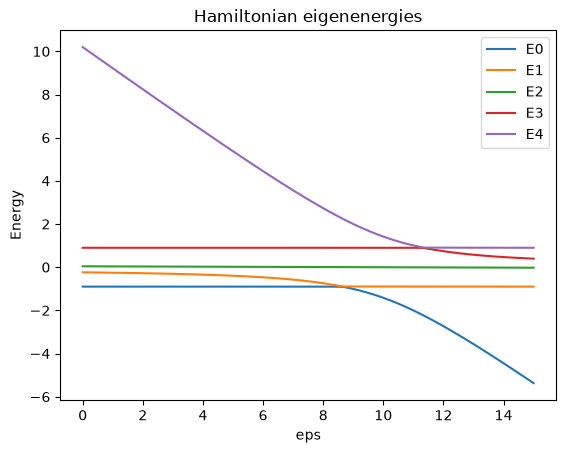

In [3]:
dqd_model.plot_eigenvalues();

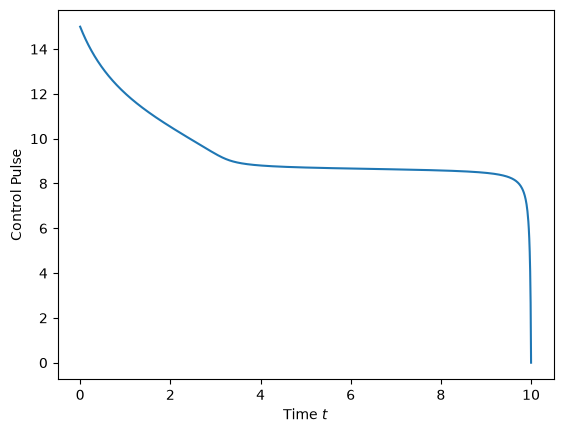

In [4]:
# ----- Solve for optimal pulse -----
dqd_model.solve_problem(pulse_accuracy=int(1000))

pulse = dqd_model.synthesize_pulse(duration=10)
pulse.plot_pulse();

# Time dynamics

Here we can ananlyze again the resulting state transfer fidelities for the geometric fast-QUAD and the FAQUAD:

In [5]:
def fidelity_vs_time(durations, model, alpha=2, beta=2):
    model.set_control(alpha=alpha, beta=beta)
    model.solve_problem(pulse_accuracy=int(1000))

    fidelities = []
    for duration in durations:
        dynamics = gq.Dynamics(duration=duration, model=model)
        fidelities.append(dynamics.state_fidelity())

    return np.array(fidelities)

In [6]:
durations = np.linspace(0.1, 1000, 200)

# Takes roughly between 1 and 2 minutes to run locally
fidelities_geometric = fidelity_vs_time(durations, dqd_model, alpha=2, beta=2)
fidelities_faquad = fidelity_vs_time(durations, dqd_model, alpha=4, beta=2)

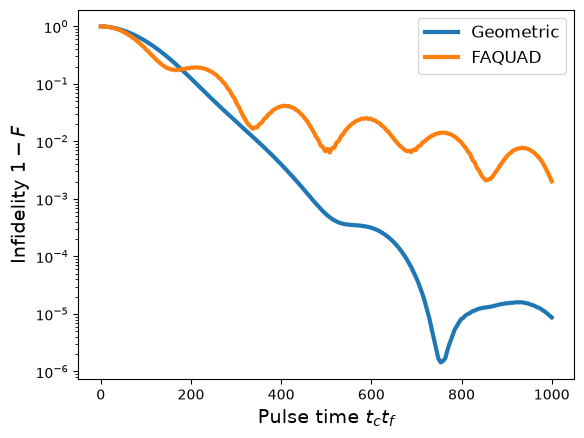

In [7]:
plt.plot(durations, 1 - fidelities_geometric, label="Geometric", lw=3)
plt.plot(durations, 1 - fidelities_faquad, label="FAQUAD", lw=3)
plt.yscale("log")
plt.ylabel("Infidelity $1-F$", fontsize=14)
plt.xlabel("Pulse time $t_c t_f$", fontsize=14)
plt.legend(fontsize=12)
plt.show();

# $(\alpha,\beta)$ fidelity sweep: pure adiabatic evolution


The choice of $\alpha$ and $\beta$ (and their diabatic counterparts) allows for smooth deformation of existing adiabatic pulses. Therefore, for any given parameter setting it might be helpful to study the set of possible adiabatic pulses. 

As a single pulse can always be rescaled for all possible total pulse times, we can efficiently optimize the search by using the `joblib` Python package

In [8]:
# joblib is an additional Python package for parallel computing
import itertools

from joblib import Parallel, delayed

In [9]:
def optimal_fidelity_time_map(durations, model, alphas, betas, n_jobs=-1):
    """
    Function that computes the fidelity map for a range of alpha and beta values over a range of durations.
    The function relies on the definition of fidelity_vs_time() from above.
    """
    results = Parallel(n_jobs=n_jobs)(
        delayed(fidelity_vs_time)(durations, model, alpha=alpha, beta=beta)
        for alpha, beta in itertools.product(alphas, betas)
    )

    fidelities = np.array(results).reshape(len(alphas), len(betas), len(durations))

    max_fidelities = np.max(fidelities, axis=2)
    best_times = durations[np.argmax(fidelities, axis=2)]

    return max_fidelities, best_times

In [10]:
durations_2d = np.linspace(0.1, 1000, 100)

alphas = np.linspace(0, 4, 7)
betas = np.linspace(0, 4, 7)

optimal_fidelities, best_times = optimal_fidelity_time_map(durations_2d, dqd_model, alphas, betas)

Below we plot the resulting heatmaps for the optimal fidelity and the corresponding total pulse time for a set of possible ($\alpha,\beta$)

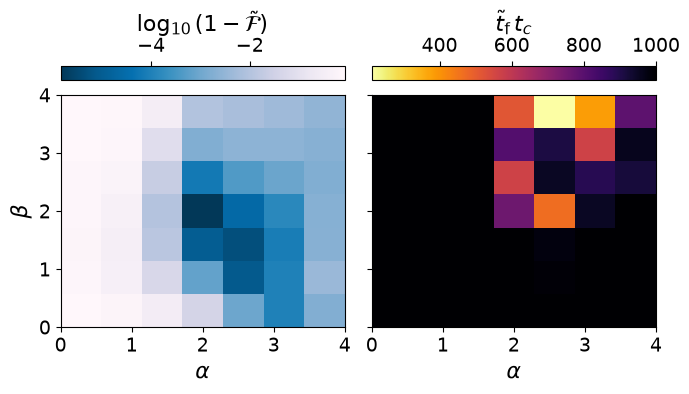

In [11]:
fontsizes = 14
fontsize_label = 16
colorbar_loc = "top"
cmap_coloring_fid = "PuBu_r"
extent = [min(alphas), max(alphas), min(betas), max(betas)]

fig, axs = plt.subplots(1, 2, figsize=(7, 4), sharey=True)

# --- Left Plot: Optimal Fidelity ---
fidelity_error = np.log10(1 - optimal_fidelities.T)

im0 = axs[0].imshow(
    fidelity_error, origin="lower", aspect="auto", interpolation="none", extent=extent, cmap=cmap_coloring_fid
)
axs[0].set_xlabel(r"$\alpha$", fontsize=fontsize_label)
axs[0].set_ylabel(r"$\beta$", fontsize=fontsize_label)
axs[0].tick_params(labelsize=fontsizes)

cbar0 = plt.colorbar(im0, ax=axs[0], location=colorbar_loc, pad=0.05)
cbar0.set_label(r"$\log_{10}(1 - \tilde{\mathcal{F}})$", size=fontsize_label)
cbar0.ax.tick_params(labelsize=fontsizes)

# --- Right Plot: Best Times ---
im1 = axs[1].imshow(best_times.T, origin="lower", aspect="auto", interpolation="none", extent=extent, cmap="inferno_r")
axs[1].set_xlabel(r"$\alpha$", fontsize=fontsize_label)
axs[1].tick_params(labelsize=fontsizes)

cbar1 = plt.colorbar(im1, ax=axs[1], location=colorbar_loc, pad=0.05)
cbar1.set_label(r"$\tilde{t}_\text{f}\,t_c$", size=fontsize_label)
cbar1.ax.tick_params(labelsize=fontsizes)

plt.tight_layout()
plt.show();

# Combined plotting (first run both optimizations individually)

This is the code to obtain the plot from the accompanying article.

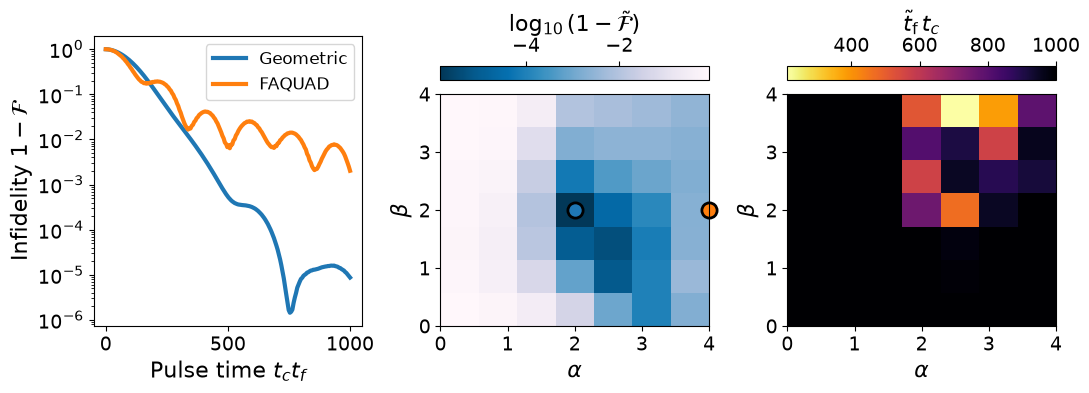

In [12]:
fontsizes = 14
fontsize_label = 16
colorbar_loc = "top"
cmap_coloring_fid = "PuBu_r"
extent = [min(alphas), max(alphas), min(betas), max(betas)]

fig, axs = plt.subplots(1, 3, figsize=(11, 4))

axs[0].plot(durations, 1 - fidelities_geometric, label="Geometric", lw=3)
axs[0].plot(durations, 1 - fidelities_faquad, label="FAQUAD", lw=3)
axs[0].set_yscale("log")
axs[0].set_ylabel(r"Infidelity $1-\mathcal{F}$", fontsize=fontsize_label)
axs[0].set_xlabel("Pulse time $t_c t_f$", fontsize=fontsize_label)
axs[0].tick_params(labelsize=fontsizes)
axs[0].legend(fontsize=12)

infidelity_opt = np.log10(1 - optimal_fidelities.T)

im1 = axs[1].imshow(
    infidelity_opt, origin="lower", aspect="auto", interpolation="none", extent=extent, cmap=cmap_coloring_fid
)
axs[1].set_xlabel(r"$\alpha$", fontsize=fontsize_label)
axs[1].set_ylabel(r"$\beta$", fontsize=fontsize_label)
axs[1].tick_params(labelsize=fontsizes)

axs[1].scatter(2, 2, s=120, label="Geometric", edgecolor="black", linewidths=2)
axs[1].scatter(4, 2, s=120, label="FAQUAD", edgecolor="black", linewidths=2, clip_on=False)

cbar1 = plt.colorbar(im1, ax=axs[1], location=colorbar_loc, pad=0.05)
cbar1.set_label(r"$\log_{10}(1 - \tilde{\mathcal{F}})$", size=fontsize_label)
cbar1.ax.tick_params(labelsize=fontsizes)

im2 = axs[2].imshow(best_times.T, origin="lower", aspect="auto", interpolation="none", extent=extent, cmap="inferno_r")
axs[2].set_xlabel(r"$\alpha$", fontsize=fontsize_label)
axs[2].set_ylabel(r"$\beta$", fontsize=fontsize_label)
axs[2].tick_params(labelsize=fontsizes)

cbar2 = plt.colorbar(im2, ax=axs[2], location=colorbar_loc, pad=0.05)
cbar2.set_label(r"$\tilde{t}_\text{f}\,t_c$", size=fontsize_label)
cbar2.ax.tick_params(labelsize=fontsizes)

plt.tight_layout()
plt.show();

About

In [13]:
gq.about()


geodesiq: geometric optimal control
Authors:            Christian Ventura Meinersen & David Fernández Fernández
geodesiq Version:   0.4.0
Python Version:     3.14.6 (cpython)
Number of CPUs:     24
Platform Info:      Windows (11, AMD64)

Core Dependencies:
Numpy Version:      2.4.6
Scipy Version:      1.17.1
QuTiP Version:      5.3.0
Matplotlib Version: 3.11.0

Please cite geodesiq in your publication.
See: https://github.com/geodesiq-control/geodesiq-control#citing-geodesiq
